In [1]:
# ============================================================
# IMPORTS AND CONFIGURATION
# ============================================================

import warnings
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

feature_cols = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "CDP"]
target_cols = ["TEY", "CO", "NOX"]


In [2]:
# ============================================================
# LOCATE AND LOAD DATASET
# ============================================================

PROJECT_DIR = Path.cwd()
PROJECT_ROOT = PROJECT_DIR.parent if PROJECT_DIR.name.lower() == "notebook" else PROJECT_DIR
OUT_DIR = PROJECT_ROOT / "outputs" / "multi_objective_optimization"
OUT_DIR.mkdir(parents=True, exist_ok=True)

possible_data_dirs = [PROJECT_ROOT / "data", PROJECT_DIR / "data"]
DATA_DIR = next((path for path in possible_data_dirs if list(path.glob("gt_*.csv"))), possible_data_dirs[0])

if not list(DATA_DIR.glob("gt_*.csv")):
    zip_candidates = [
        PROJECT_ROOT / "gas+turbine+co+and+nox+emission+data+set.zip",
        PROJECT_DIR / "gas+turbine+co+and+nox+emission+data+set.zip"
    ]
    zip_path = next((p for p in zip_candidates if p.exists()), None)
    if zip_path is not None:
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(DATA_DIR)

files = sorted(DATA_DIR.glob("gt_20*.csv"))
if not files:
    raise FileNotFoundError("Place the five gt_2011.csv–gt_2015.csv files in a data folder, or place the dataset ZIP beside this notebook.")

frames = []
for file in files:
    frame = pd.read_csv(file)
    frame["Year"] = int(file.stem.split("_")[-1])
    frames.append(frame)

data = pd.concat(frames, ignore_index=True)
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=feature_cols + target_cols + ["Year"]).reset_index(drop=True)

development_data = data[data["Year"] <= 2014].copy()
comparison_data = data[data["Year"] == 2015].copy()
X_train = development_data[feature_cols]

print("Dataset directory:", DATA_DIR)
print("Output directory:", OUT_DIR)
print("Dataset shape:", data.shape)
print("Development years:", sorted(development_data["Year"].unique()))
print("2015 comparison rows:", len(comparison_data))


Dataset directory: c:\Users\devra\Music\gas-turbine-ml\data
Output directory: c:\Users\devra\Music\gas-turbine-ml\outputs\multi_objective_optimization
Dataset shape: (36733, 12)
Development years: [np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014)]
2015 comparison rows: 7384


In [3]:
# ============================================================
# TRAIN SELECTED TEY MODEL: RANDOM FOREST
# ============================================================

rf_parameter_grid = {
    "n_estimators": [150, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "max_features": [1.0, "sqrt"]
}

tscv = TimeSeriesSplit(n_splits=5)
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
    param_distributions=rf_parameter_grid,
    n_iter=4,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True
)
rf_search.fit(X_train, development_data["TEY"])
tey_model = rf_search.best_estimator_
print("TEY RF CV MAE:", round(-rf_search.best_score_, 4))
print("TEY RF parameters:", rf_search.best_params_)


TEY RF CV MAE: 0.892
TEY RF parameters: {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 30}


In [4]:
# ============================================================
# TRAIN SELECTED CO MODEL: GRADIENT BOOSTING
# ============================================================

gb_params = {
    "n_estimators": 100,
    "learning_rate": 0.05,
    "max_depth": 2,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "subsample": 0.8,
    "loss": "squared_error",
    "random_state": RANDOM_STATE
}

co_model = GradientBoostingRegressor(**gb_params)
co_model.fit(X_train, development_data["CO"])
print("CO Gradient Boosting model trained.")


CO Gradient Boosting model trained.


In [5]:
# ============================================================
# TRAIN SELECTED NOX MODEL: LINEAR REGRESSION
# ============================================================

nox_model = LinearRegression()
nox_model.fit(X_train, development_data["NOX"])
print("NOX Linear Regression model trained.")


NOX Linear Regression model trained.


In [6]:
# ============================================================
# GENERATE CANDIDATE OPERATING CONDITIONS
# ============================================================

# Use observed feature combinations from 2011–2014 to avoid creating
# unsupported combinations by independently sampling each feature.
candidates = development_data[feature_cols].drop_duplicates().reset_index(drop=True)

candidate_predictions = pd.DataFrame({
    "Predicted_TEY": tey_model.predict(candidates),
    "Predicted_CO": co_model.predict(candidates),
    "Predicted_NOX": nox_model.predict(candidates)
})

optimization_results = pd.concat([candidates, candidate_predictions], axis=1)
optimization_results.to_csv(OUT_DIR / "optimization_candidate_predictions.csv", index=False)

print("Unique historical operating combinations:", len(candidates))
display(optimization_results.head())


Unique historical operating combinations: 29342


,AT,AP,AH,AFDP,GTEP,TIT,TAT,CDP,Predicted_TEY,Predicted_CO,Predicted_NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,11.898,134.703581,1.498983,83.805790
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,11.892,134.702698,1.498983,83.849883
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,12.042,135.025267,1.492058,82.746718
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,11.990,135.015725,1.498983,83.489224
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,11.910,134.748526,1.498983,84.103594


In [7]:
# ============================================================
# IDENTIFY PARETO-OPTIMAL OPERATING POINTS
# ============================================================

# Objectives: maximize TEY, minimize CO, minimize NOX.
values = optimization_results[["Predicted_TEY", "Predicted_CO", "Predicted_NOX"]].to_numpy()
objectives = np.column_stack([-values[:, 0], values[:, 1], values[:, 2]])

# Fenwick tree for efficient dominance queries in three objectives.
order = np.lexsort((objectives[:, 2], objectives[:, 1], objectives[:, 0]))
second_values = np.unique(objectives[:, 1])
second_rank = np.searchsorted(second_values, objectives[:, 1]) + 1
tree = np.full(len(second_values) + 1, np.inf)
pareto_mask = np.ones(len(objectives), dtype=bool)

def query_min(index):
    result = np.inf
    while index > 0:
        result = min(result, tree[index])
        index -= index & -index
    return result

def update_min(index, value):
    while index < len(tree):
        tree[index] = min(tree[index], value)
        index += index & -index

for idx in order:
    rank = second_rank[idx]
    if query_min(rank) <= objectives[idx, 2]:
        pareto_mask[idx] = False
    update_min(rank, objectives[idx, 2])

optimization_results["Pareto_Optimal"] = pareto_mask
pareto_results = optimization_results.loc[pareto_mask].copy()
pareto_results = pareto_results.sort_values("Predicted_TEY", ascending=False)
pareto_results.to_csv(OUT_DIR / "pareto_optimal_operating_points.csv", index=False)

print("Pareto-optimal points:", len(pareto_results))
print("Share of candidates:", round(100 * len(pareto_results) / len(optimization_results), 2), "%")
display(pareto_results.head(15).round(4))

Pareto-optimal points: 56
Share of candidates: 0.19 %


,AT,AP,AH,AFDP,GTEP,TIT,TAT,CDP,Predicted_TEY,Predicted_CO,Predicted_NOX,Pareto_Optimal
7750,3.4226,1017.6,85.443,5.9684,37.172,1100.0,513.09,15.081,173.4453,1.0806,77.1668,True
7749,3.7054,1017.1,85.930,5.9800,37.189,1099.5,513.06,15.055,173.4401,1.0806,76.6512,True
7748,4.0273,1016.6,87.783,5.9883,36.973,1099.5,513.47,15.031,173.4062,1.0865,76.1040,True
22184,5.6777,1025.3,92.704,4.6708,36.803,1099.8,521.11,14.849,171.8922,1.0926,65.3838,True
22183,6.3239,1024.7,88.633,4.6440,36.657,1099.6,521.08,14.867,171.7435,1.0865,65.7724,True
22185,5.4158,1026.1,82.718,4.6417,36.950,1100.0,521.10,14.811,171.6660,1.0806,68.3719,True
22182,7.2022,1023.6,80.694,4.6069,36.399,1099.6,522.05,14.824,170.1546,1.0806,66.8161,True
22181,7.1267,1022.4,85.064,4.6292,36.341,1100.5,523.17,14.791,169.5384,1.0806,65.7889,True
22653,5.6979,1031.2,94.119,4.6085,34.479,1100.0,529.80,14.362,167.0225,1.0926,64.5665,True
23367,10.5900,1018.6,78.822,4.9672,36.216,1100.0,526.83,14.458,165.2021,1.0806,62.9811,True


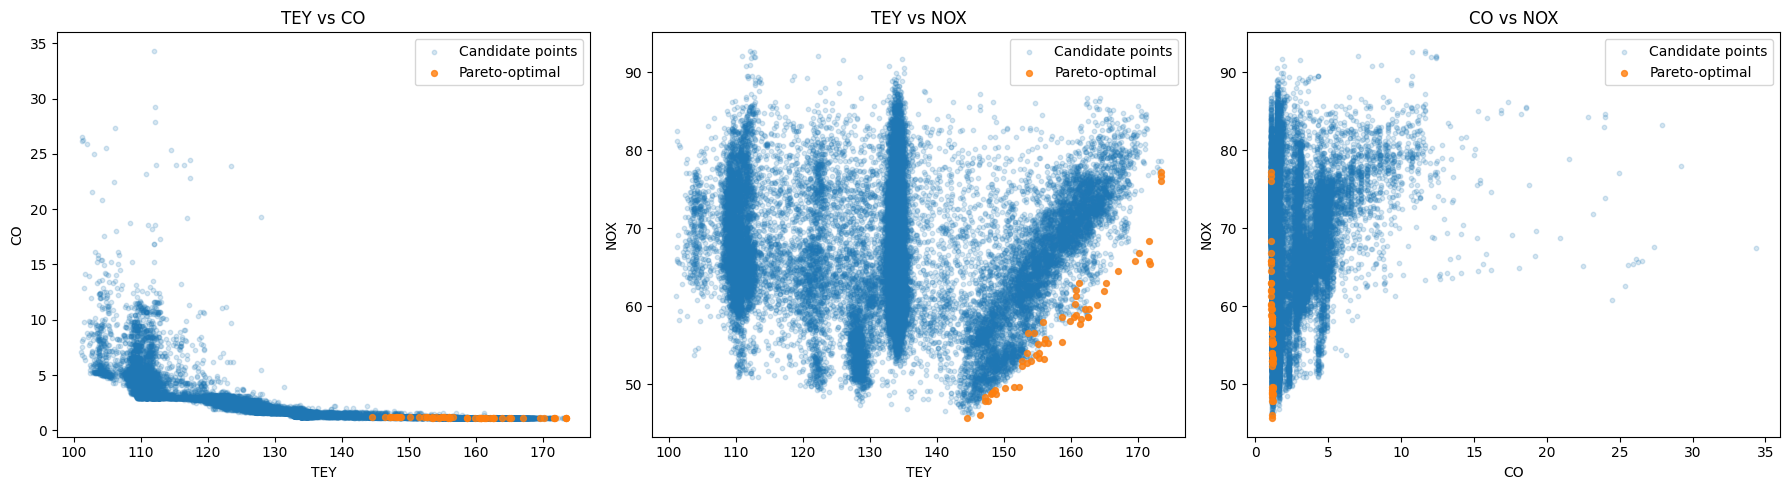

In [8]:
# ============================================================
# VISUALIZE THREE OBJECTIVE TRADE-OFFS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plots = [
    ("Predicted_TEY", "Predicted_CO", "TEY vs CO"),
    ("Predicted_TEY", "Predicted_NOX", "TEY vs NOX"),
    ("Predicted_CO", "Predicted_NOX", "CO vs NOX")
]

for ax, (x_col, y_col, title) in zip(axes, plots):
    ax.scatter(
        optimization_results[x_col], optimization_results[y_col],
        s=10, alpha=0.18, label="Candidate points"
    )
    ax.scatter(
        pareto_results[x_col], pareto_results[y_col],
        s=18, alpha=0.8, label="Pareto-optimal"
    )
    ax.set_xlabel(x_col.replace("Predicted_", ""))
    ax.set_ylabel(y_col.replace("Predicted_", ""))
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig(OUT_DIR / "pareto_tradeoff_plots.png", dpi=300, bbox_inches="tight")
plt.show()


In [9]:
# ============================================================
# SUMMARIZE EXTREME AND BALANCED CANDIDATES
# ============================================================

summary = pd.DataFrame([
    {"Selection": "Highest predicted TEY", **optimization_results.loc[optimization_results["Predicted_TEY"].idxmax()].to_dict()},
    {"Selection": "Lowest predicted CO", **optimization_results.loc[optimization_results["Predicted_CO"].idxmin()].to_dict()},
    {"Selection": "Lowest predicted NOX", **optimization_results.loc[optimization_results["Predicted_NOX"].idxmin()].to_dict()}
])

summary.to_csv(OUT_DIR / "optimization_extreme_candidates.csv", index=False)
display(summary.round(4))

print("Optimization analysis completed.")
print("These are model-supported comparisons of historical operating combinations, not causal setpoint recommendations or validated safe operating conditions.")


,Selection,AT,AP,AH,AFDP,GTEP,TIT,TAT,CDP,Predicted_TEY,Predicted_CO,Predicted_NOX,Pareto_Optimal
0,Highest predicted TEY,3.4226,1017.6,85.443,5.9684,37.172,1100.0,513.09,15.081,173.4453,1.0806,77.1668,True
1,Lowest predicted CO,10.7220,1016.5,80.263,4.7526,32.739,1100.2,528.93,14.049,160.9841,1.0806,71.9188,False
2,Lowest predicted NOX,32.1570,1006.7,70.366,5.0399,29.921,1099.6,547.63,13.026,144.4951,1.1730,45.6014,True


Optimization analysis completed.
These are model-supported comparisons of historical operating combinations, not causal setpoint recommendations or validated safe operating conditions.


Pareto-optimal candidates: 56
Pareto share of all candidates: 0.19 %

Representative Pareto solutions:


,Selection,AT,AP,AH,AFDP,GTEP,TIT,TAT,CDP,Predicted_TEY,Predicted_CO,Predicted_NOX,TEY_Score,CO_Score,NOX_Score,Ideal_Point_Distance
0,Highest TEY among Pareto points,3.4226,1017.6,85.443,5.9684,37.172,1100.0,513.09,15.081,173.4453,1.0806,77.1668,1.0000,1.0000,0.0000,0.5774
1,Lowest CO among Pareto points,3.4226,1017.6,85.443,5.9684,37.172,1100.0,513.09,15.081,173.4453,1.0806,77.1668,1.0000,1.0000,0.0000,0.5774
2,Lowest NOX among Pareto points,32.1570,1006.7,70.366,5.0399,29.921,1099.6,547.63,13.026,144.4951,1.1730,45.6014,0.0000,0.1155,1.0000,0.7708
3,Balanced compromise (equal-weight distance),10.5530,1016.8,100.070,6.7386,35.167,1100.1,528.79,14.288,163.9847,1.0926,60.1422,0.6732,0.8845,0.5393,0.3328



Top 10 compromise candidates:


,AT,AP,AH,AFDP,GTEP,TIT,TAT,CDP,Predicted_TEY,Predicted_CO,Predicted_NOX,Ideal_Point_Distance
22888,10.5530,1016.8,100.070,6.7386,35.167,1100.1,528.79,14.288,163.9847,1.0926,60.1422,0.3328
24117,9.9031,1010.1,99.557,5.1502,35.406,1100.2,527.26,14.346,164.9372,1.0926,61.9630,0.3504
23367,10.5900,1018.6,78.822,4.9672,36.216,1100.0,526.83,14.458,165.2021,1.0806,62.9811,0.3579
22889,11.3340,1016.5,100.070,6.6262,34.480,1100.1,530.87,14.164,162.1873,1.1056,59.6145,0.3678
22184,5.6777,1025.3,92.704,4.6708,36.803,1099.8,521.11,14.849,171.8922,1.0926,65.3838,0.3692
22183,6.3239,1024.7,88.633,4.6440,36.657,1099.6,521.08,14.867,171.7435,1.0865,65.7724,0.3719
28438,15.2140,1015.9,83.654,3.9147,34.121,1099.9,528.81,14.284,160.6494,1.0905,60.2670,0.3743
24118,13.2720,1010.1,99.891,5.0188,34.221,1100.0,531.16,14.057,160.8178,1.1056,58.8056,0.3754
22653,5.6979,1031.2,94.119,4.6085,34.479,1100.0,529.80,14.362,167.0225,1.0926,64.5665,0.3757
22181,7.1267,1022.4,85.064,4.6292,36.341,1100.5,523.17,14.791,169.5384,1.0806,65.7889,0.3774


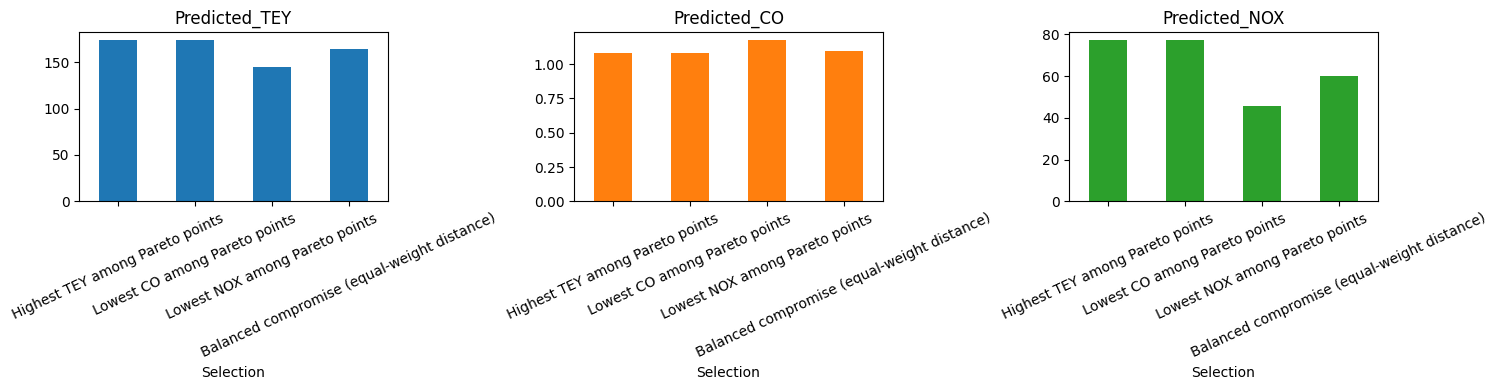


Files saved in: c:\Users\devra\Music\gas-turbine-ml\outputs\multi_objective_optimization
No CO or NOX limits were imposed.
The balanced candidate is a mathematical compromise within this Pareto set,
not a universally best, causal, safe, or validated turbine operating point.


In [10]:
# ============================================================
# PARETO SOLUTION RANKING AND COMPROMISE ANALYSIS
# ============================================================

objective_cols = ["Predicted_TEY", "Predicted_CO", "Predicted_NOX"]
feature_cols_for_display = feature_cols

pareto_analysis = pareto_results.copy()

tey_min, tey_max = pareto_analysis["Predicted_TEY"].min(), pareto_analysis["Predicted_TEY"].max()
co_min, co_max = pareto_analysis["Predicted_CO"].min(), pareto_analysis["Predicted_CO"].max()
nox_min, nox_max = pareto_analysis["Predicted_NOX"].min(), pareto_analysis["Predicted_NOX"].max()

tey_range = max(tey_max - tey_min, 1e-12)
co_range = max(co_max - co_min, 1e-12)
nox_range = max(nox_max - nox_min, 1e-12)

# Normalize each objective to [0, 1], where 1 is best.
pareto_analysis["TEY_Score"] = (
    (pareto_analysis["Predicted_TEY"] - tey_min) / tey_range
)
pareto_analysis["CO_Score"] = (
    (co_max - pareto_analysis["Predicted_CO"]) / co_range
)
pareto_analysis["NOX_Score"] = (
    (nox_max - pareto_analysis["Predicted_NOX"]) / nox_range
)

# Equal-weight distance from the ideal point; this is a compromise indicator,
# not a new physical objective or a claim that all objectives are equally important.
pareto_analysis["Ideal_Point_Distance"] = np.sqrt(
    (1 - pareto_analysis["TEY_Score"]) ** 2
    + (1 - pareto_analysis["CO_Score"]) ** 2
    + (1 - pareto_analysis["NOX_Score"]) ** 2
) / np.sqrt(3)

balanced_candidate = pareto_analysis.loc[
    pareto_analysis["Ideal_Point_Distance"].idxmin()
].copy()

pareto_extremes = pd.DataFrame([
    pd.concat([pareto_analysis.loc[pareto_analysis["Predicted_TEY"].idxmax()], pd.Series({"Selection": "Highest TEY among Pareto points"})]),
    pd.concat([pareto_analysis.loc[pareto_analysis["Predicted_CO"].idxmin()], pd.Series({"Selection": "Lowest CO among Pareto points"})]),
    pd.concat([pareto_analysis.loc[pareto_analysis["Predicted_NOX"].idxmin()], pd.Series({"Selection": "Lowest NOX among Pareto points"})]),
    pd.concat([balanced_candidate, pd.Series({"Selection": "Balanced compromise (equal-weight distance)"})])
])

pareto_extremes = pareto_extremes[
    ["Selection"] + feature_cols_for_display + objective_cols
    + ["TEY_Score", "CO_Score", "NOX_Score", "Ideal_Point_Distance"]
]
pareto_extremes.to_csv(
    OUT_DIR / "pareto_representative_solutions.csv", index=False
)

pareto_analysis = pareto_analysis.sort_values("Ideal_Point_Distance")
pareto_analysis.to_csv(
    OUT_DIR / "pareto_ranked_solutions.csv", index=False
)

print("Pareto-optimal candidates:", len(pareto_analysis))
print("Pareto share of all candidates:",
      round(100 * len(pareto_analysis) / len(optimization_results), 2), "%")
print("\nRepresentative Pareto solutions:")
display(pareto_extremes.round(4))

print("\nTop 10 compromise candidates:")
display(pareto_analysis[
    feature_cols_for_display + objective_cols + ["Ideal_Point_Distance"]
].head(10).round(4))

# Compare objective values for the four representative solutions.
plot_data = pareto_extremes.set_index("Selection")[objective_cols]
ax = plot_data.plot(kind="bar", subplots=True, layout=(1, 3),
                    figsize=(15, 4), legend=False, rot=25)
plt.tight_layout()
plt.savefig(
    OUT_DIR / "pareto_representative_solution_comparison.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("\nFiles saved in:", OUT_DIR)
print("No CO or NOX limits were imposed.")
print("The balanced candidate is a mathematical compromise within this Pareto set,")
print("not a universally best, causal, safe, or validated turbine operating point.")